# Did Your Savings Beat Inflation? Nigeria, 2006–2026

Nigerians save in naira bank accounts, fixed deposits, Treasury bills or US dollars.
Inflation often ran far above the interest banks paid, so money in the bank may have
grown in naira while buying less and less.

**Goal:** measure how each common way of saving performed **after inflation**, using
monthly data from the Central Bank of Nigeria (CBN).

> **This is analysis, not financial advice.** Past returns do not predict future returns.

## 1. Setup

**Question:** Do we have the right tools loaded and working?

We use four packages:
- `pandas` for tables of data
- `matplotlib` for charts
- `requests` to download data from the CBN website
- `pathlib` (built into Python) for file and folder paths

In [27]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import requests

# Folders for the saved data snapshot and the README charts
DATA_DIR = Path("data")
IMAGES_DIR = Path("images")
DATA_DIR.mkdir(exist_ok=True)
IMAGES_DIR.mkdir(exist_ok=True)

print("Python:    ", sys.version.split()[0])
print("pandas:    ", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("requests:  ", requests.__version__)

Python:     3.15.0
pandas:     3.1.0
matplotlib: 3.11.2
requests:   2.34.2


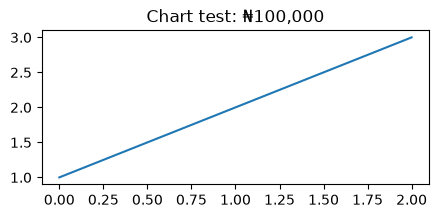

In [28]:
# Quick chart test: matplotlib had font problems on Python 3.15 in an earlier project.
# If this draws a line with the title below, charts work.
fig, ax = plt.subplots(figsize=(5, 2))
ax.plot([1, 2, 3])
ax.set_title("Chart test: ₦100,000")
plt.show()

**Finding:** All packages load and matplotlib can draw a chart, including the naira sign (₦).
The environment is ready for the data pull.

## 2. Data pull from the CBN

**Question:** Can we download 20 years of Nigerian interest rates, inflation and the
naira–dollar exchange rate, and combine them into one clean monthly table?

The CBN website gets its numbers from three **JSON feeds** (an API: a web address that
returns data for programs instead of a page for people):

| Feed | What it holds |
|---|---|
| `GetAllMoneyMarketIndicators` | Monthly interest rates from Jan 2006: savings, fixed deposits, Treasury bills, MPR… |
| `GetAllInflationRates` | Monthly year-on-year inflation from Jan 2003 |
| `GetAllExchangeRates` | Daily official exchange rates for many currencies |

These feeds are **undocumented**, so they could change or disappear. That's why, every
time the download works, we save a **CSV snapshot**. If the download fails, the notebook
loads the snapshot instead, so it still runs offline.

In [29]:
# The CBN data feeds (undocumented, so they could change without notice)
BASE_URL = "https://www.cbn.gov.ng/api/"
FEEDS = {
    "money_market": "GetAllMoneyMarketIndicators",
    "inflation": "GetAllInflationRates",
    "exchange_rates": "GetAllExchangeRates",
}

# Some servers refuse requests that don't look like they come from a web browser
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/130.0 Safari/537.36"
}

SNAPSHOT_PATH = DATA_DIR / "cbn_savings_data.csv"


def fetch_feed(feed_name):
    """Download one CBN feed and return it as a DataFrame (every value is still text)."""
    response = requests.get(BASE_URL + feed_name, headers=HEADERS, timeout=120)
    response.raise_for_status()  # stop with an error if the server says no (e.g. 404 or 500)
    return pd.DataFrame(response.json())

### Cleaning each feed

The feeds send every number as **text** (for example `"5.36"`), so we convert them with
`pd.to_numeric`. Using `errors="coerce"` turns anything that isn't a number, such as a
blank `""`, into `NaN` (missing) instead of crashing.

The feeds also store dates as two columns, `tyear` and `tmonth`. We combine them into
one `month` date (the 1st of each month), so the three tables can be lined up.

In [30]:
# The interest rate columns in the money market feed (all in % per year)
RATE_COLUMNS = [
    "savingsDeposit", "oneMonthDeposit", "threeMonthsDeposit", "sixMonthsDeposit",
    "twelveMonthsDeposit", "treasuryBill", "mpr", "mrr",
    "interBankCallRate", "primeLending", "maxLending",
]


def add_month_column(df):
    """Combine the tyear and tmonth columns into one date: the 1st of each month."""
    df["month"] = pd.to_datetime({"year": df["tyear"], "month": df["tmonth"], "day": 1})
    return df


def clean_money_market(raw):
    df = add_month_column(raw.copy())
    for col in RATE_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    # The feed is newest-first; sort it oldest-first
    return df[["month"] + RATE_COLUMNS].sort_values("month")


def clean_inflation(raw):
    df = add_month_column(raw.copy())
    # "YearOn" = year-on-year: how much prices rose compared with the same month last year
    df["inflation"] = pd.to_numeric(df["allItemsYearOn"], errors="coerce")
    df["food_inflation"] = pd.to_numeric(df["foodYearOn"], errors="coerce")
    return df[["month", "inflation", "food_inflation"]].sort_values("month")

The exchange rate feed needs more work:
- It holds **every currency**, and some names have stray spaces or tabs
  (`"US DOLLAR"` and `"US DOLLAR "` both appear). We strip those before picking the dollar.
- It is **daily**, but the other feeds are monthly. We take the **average rate of each month**.
- A few days appear twice, so we keep one row per day.

`centralrate` is the CBN's official rate: how many naira one US dollar cost.

In [31]:
def clean_usd(raw):
    df = raw.copy()
    df["currency"] = df["currency"].str.strip()  # remove stray spaces and tabs
    usd = df[df["currency"] == "US DOLLAR"].copy()

    usd["date"] = pd.to_datetime(usd["ratedate"])
    usd["usd_ngn"] = pd.to_numeric(usd["centralrate"], errors="coerce")
    usd = usd.drop_duplicates(subset="date")  # one row per day

    # resample("MS") groups the days into months, dated at the Month Start (the 1st)
    monthly = usd.set_index("date")["usd_ngn"].resample("MS").mean()
    return monthly.reset_index().rename(columns={"date": "month"})

### Download, combine, save (or fall back to the snapshot)

We **merge** the three tables on `month`. The money market table goes first and decides
which months we keep (Jan 2006 onwards), because without interest rates there is nothing
to compare.

`try` / `except` means: *try the download; if a network error happens, run the
`except` part instead.* We only catch download errors (`RequestException`) and broken
JSON (`ValueError`), so a mistake in our own code still shows up as an error.

In [32]:
try:
    print("Downloading CBN feeds (the exchange rate feed is about 8 MB)...")
    money_market = clean_money_market(fetch_feed(FEEDS["money_market"]))
    inflation = clean_inflation(fetch_feed(FEEDS["inflation"]))
    usd = clean_usd(fetch_feed(FEEDS["exchange_rates"]))

    data = (
        money_market
        .merge(inflation, on="month", how="left")
        .merge(usd, on="month", how="left")
    )
    data.to_csv(SNAPSHOT_PATH, index=False)
    print(f"Live data downloaded. Snapshot saved to {SNAPSHOT_PATH}")

except (requests.RequestException, ValueError) as error:
    print(f"Download failed: {error}")
    print(f"Using the saved snapshot instead: {SNAPSHOT_PATH}")
    data = pd.read_csv(SNAPSHOT_PATH, parse_dates=["month"])

Live data downloaded. Snapshot saved to data\cbn_savings_data.csv


In [33]:
print("Rows (months):", len(data))
print("From", data["month"].min().date(), "to", data["month"].max().date())
data.head()

Rows (months): 249
From 2006-01-01 to 2026-09-01


,month,savingsDeposit,oneMonthDeposit,threeMonthsDeposit,sixMonthsDeposit,twelveMonthsDeposit,treasuryBill,mpr,mrr,interBankCallRate,primeLending,maxLending,inflation,food_inflation,usd_ngn
0,2006-01-01,4.50,7.88,9.95,8.55,8.64,13.68,0.0,13.0,27.06,16.69,18.23,10.7,14.7,128.500000
1,2006-02-01,2.96,9.13,9.68,8.95,8.36,11.49,0.0,13.0,5.59,16.57,18.14,10.8,10.5,127.825000
2,2006-03-01,2.98,9.37,9.57,8.61,9.17,9.86,0.0,13.0,7.77,16.30,17.89,12.0,9.3,126.977273
3,2006-04-01,2.98,9.35,10.23,8.78,8.93,8.60,0.0,13.0,1.13,16.25,18.03,12.6,9.6,126.695000
4,2006-05-01,2.95,9.40,10.26,9.16,9.09,6.65,0.0,13.0,1.57,16.97,18.36,10.5,8.6,126.679524


In [34]:
data.tail()

,month,savingsDeposit,oneMonthDeposit,threeMonthsDeposit,sixMonthsDeposit,twelveMonthsDeposit,treasuryBill,mpr,mrr,interBankCallRate,primeLending,maxLending,inflation,food_inflation,usd_ngn
244,2026-05-01,7.24,12.61,9.89,8.51,10.88,15.95,26.5,NaN,NaN,19.10,34.78,15.93,16.96,1369.494706
245,2026-06-01,7.32,12.51,10.05,8.01,10.32,16.16,26.5,NaN,NaN,19.06,33.16,15.91,17.52,1366.490167
246,2026-07-01,7.36,12.31,10.07,7.71,9.74,16.30,26.5,NaN,NaN,19.06,33.16,15.43,20.31,1372.752317
247,2026-08-01,7.46,12.69,10.34,7.56,10.30,16.30,26.5,NaN,22.0,17.86,29.20,15.39,19.57,1352.473120
248,2026-09-01,5.36,12.20,10.33,8.33,10.50,16.24,23.0,NaN,22.0,19.04,32.62,14.63,19.59,1326.807700


**Finding:** We have one clean monthly table: **249 months, January 2006 to September 2026**,
with every rate stored as a number. A first look already tells the story:

- In January 2006 a savings account paid **4.50%** while inflation was **10.7%**.
- One US dollar cost **₦128.50** in January 2006 and about **₦1,327** in September 2026,
  roughly **10 times** as many naira.

A few things to check in the Data Quality section:
- `mpr` shows **0.0** for early 2006. The MPR didn't exist yet, so that means *missing*, not 0%.
- `mrr` is missing for most months, because the MPR replaced it.
- `interBankCallRate` has 5 missing months (we don't use it for savings).
- Some rates jump around a lot (e.g. Treasury bills fell from 13.68% to 6.65% in early 2006,
  and the savings rate fell from 7.46% to 5.36% in the latest month). We'll check whether those are real.

The snapshot is saved in `data/cbn_savings_data.csv`, so the notebook still runs offline.

## 3. Data quality

**Question:** Can we trust these numbers? Are there blanks, fake zeros, typos or
values that disagree with official sources?

One bad number, like a 0% Treasury bill rate, would quietly break every calculation
after it. So before any analysis we check four things:
1. **Blanks:** missing values
2. **Fake zeros:** a `0` that really means "no data"
3. **Spikes:** a value that jumps and snaps back the next month (often a typo)
4. **Spot checks:** a few of our values compared with news and official sources

We keep the original `data` untouched and make our fixes in a copy called `clean`.
Every later section uses `clean`.

In [35]:
clean = data.copy()

# Count blanks and zeros in every column
quality = pd.DataFrame({
    "missing": clean.isna().sum(),
    "zeros": (clean == 0).sum(),
})
quality[(quality["missing"] > 0) | (quality["zeros"] > 0)]

,missing,zeros
treasuryBill,0,2
mpr,0,11
mrr,238,0
interBankCallRate,5,4


Three columns have zeros, and two have blanks. Let's look at each.

### The MPR / MRR switch

Until December 2006, the CBN's main interest rate was the **MRR** (Minimum Rediscount
Rate). From **11 December 2006** it was replaced by the **MPR** (Monetary Policy Rate),
starting at 10%. So in our data:
- `mrr` is blank from December 2006 on (correct: it no longer existed)
- `mpr` is `0.0` before December 2006, which is wrong: the rate didn't exist, it wasn't 0%

In [36]:
clean.loc[(clean["month"] >= "2006-09-01") & (clean["month"] <= "2007-02-01"), ["month", "mpr", "mrr"]]

,month,mpr,mrr
8,2006-09-01,0.0,14.0
9,2006-10-01,0.0,14.0
10,2006-11-01,0.0,14.0
11,2006-12-01,10.0,NaN
12,2007-01-01,10.0,NaN
13,2007-02-01,10.0,NaN


In [37]:
# Before Dec 2006 the MPR didn't exist: replace the fake zeros with NaN (missing)
clean.loc[clean["mpr"] == 0, "mpr"] = float("nan")

print("MPR zeros left:", (clean["mpr"] == 0).sum())
print("First month with an MPR:", clean.loc[clean["mpr"].notna(), "month"].min().date())

MPR zeros left: 0
First month with an MPR: 2006-12-01


### Treasury bill zeros

A 0% Treasury bill rate never happened in Nigeria. The two zeros fall in **December 2017**
and **December 2018**, right between months of 11–13%, so they mean "no figure reported".

We can't leave a gap, because later we compound a return **every month**. So we fill
each gap with the previous month's rate (`ffill`, "forward fill"). This assumes the rate
stayed the same for that one month, which is a small, reasonable guess.

In [38]:
tbill_zero = clean["treasuryBill"] == 0
print("Zero months:", clean.loc[tbill_zero, "month"].dt.strftime("%Y-%m").tolist())

clean.loc[tbill_zero, "treasuryBill"] = float("nan")
clean["treasuryBill"] = clean["treasuryBill"].ffill()

clean.loc[(clean["month"] >= "2017-11-01") & (clean["month"] <= "2018-01-01"), ["month", "treasuryBill"]]

Zero months: ['2017-12', '2018-12']


,month,treasuryBill
142,2017-11-01,13.01
143,2017-12-01,13.01
144,2018-01-01,12.27


### Interbank call rate

`interBankCallRate` (the rate banks charge each other overnight) has 4 zeros and
5 blanks. We don't use it to measure savings, so we only mark the zeros as missing
and leave the gaps.

In [39]:
clean.loc[clean["interBankCallRate"] == 0, "interBankCallRate"] = float("nan")
print("Interbank months missing:", clean["interBankCallRate"].isna().sum())

Interbank months missing: 9


### Spikes: values that jump and snap back

A real rate change usually lasts: when the CBN raises rates, they stay up. A **typo**
tends to appear for one month and disappear. So for each month we compare the value
with the **average of the month before and the month after**. If it is more than
3 percentage points away from that average, we flag it for a closer look.

(We run this *after* fixing the zeros. Otherwise the zeros, and the months next to them,
would fill the list.)

In [40]:
def find_spikes(series, threshold=3):
    """Flag months more than `threshold` points away from the average of their two neighbours."""
    neighbours_avg = (series.shift(1) + series.shift(-1)) / 2
    gap = series - neighbours_avg
    return gap[gap.abs() > threshold]


KEY_COLUMNS = ["savingsDeposit", "twelveMonthsDeposit", "treasuryBill", "mpr", "inflation"]
by_month = clean.set_index("month")

spikes = []
for col in KEY_COLUMNS:
    for month, gap in find_spikes(by_month[col]).items():
        spikes.append({"column": col, "month": month.strftime("%Y-%m"),
                       "value": by_month.loc[month, col], "gap": round(gap, 2)})

pd.DataFrame(spikes)

,column,month,value,gap
0,twelveMonthsDeposit,2009-02,16.47,4.56
1,twelveMonthsDeposit,2009-03,11.44,-4.25
2,twelveMonthsDeposit,2009-04,14.91,3.38
3,twelveMonthsDeposit,2009-11,8.91,-3.84
4,twelveMonthsDeposit,2012-12,10.63,4.50
5,treasuryBill,2011-10,15.00,3.28
6,treasuryBill,2024-01,4.33,-8.65
7,treasuryBill,2024-02,17.03,6.60
8,inflation,2006-07,3.00,-3.10
9,inflation,2024-12,34.80,3.69


A chart helps us judge these. Big moves that **last** are real history. Single-month
blips are suspects.

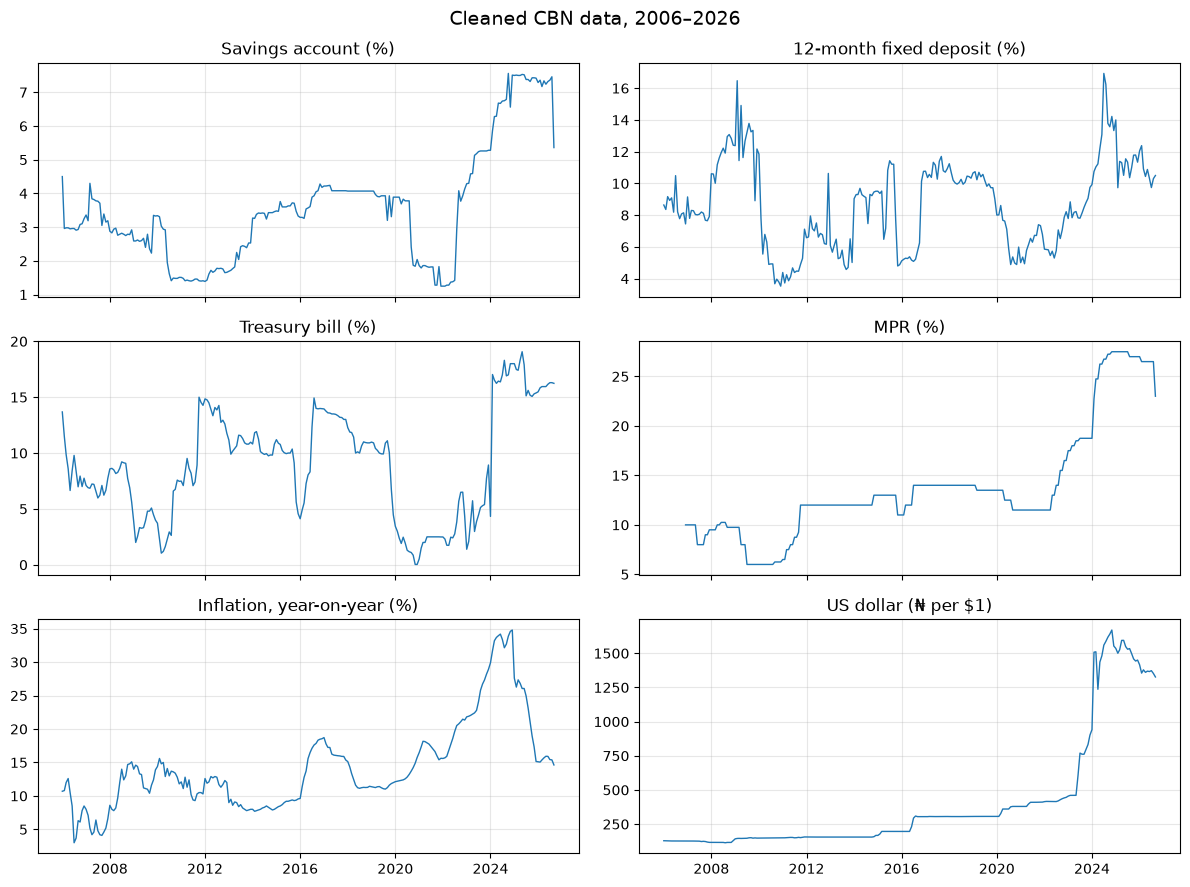

In [41]:
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)
chart_columns = KEY_COLUMNS + ["usd_ngn"]
titles = ["Savings account (%)", "12-month fixed deposit (%)", "Treasury bill (%)",
          "MPR (%)", "Inflation, year-on-year (%)", "US dollar (₦ per $1)"]

for ax, col, title in zip(axes.flat, chart_columns, titles):
    ax.plot(clean["month"], clean[col], linewidth=1)
    ax.set_title(title)
    ax.grid(alpha=0.3)

fig.suptitle("Cleaned CBN data, 2006–2026", fontsize=14)
fig.tight_layout()
plt.show()

**Our verdict on each flag:**

| Flag | Verdict | Action |
|---|---|---|
| Inflation, Jul 2006: 3.0% | A secondary source (Nairametrics) lists the same 3.00%; inflation was low through mid-2006 | Keep |
| Inflation, Dec 2024: 34.8% | NBS published 34.80%. It looks like a spike only because Jan 2025 dropped after the CPI rebasing | Keep (Section 4 handles the rebasing) |
| MPR, Dec 2006 | The MPR began that month | Keep |
| T-bill, Oct 2011 | The MPR jumped 2.75 points that month; T-bills followed | Keep |
| T-bill, Jan → Feb 2024: 4.33% → 17.03% | Matches the Feb 2024 policy shock (MPR +4 points, naira devalued). Rates stayed high afterwards | Keep |
| 12-month deposit, 2009 | Rates bounced for several months during the 2009 banking crisis, not just one | Keep, but note it's noisy |
| 12-month deposit, Dec 2012: 10.63% | A one-month blip between 6.17% and 6.09%, and nothing else moved. Likely a year-end special rate or an error | **Keep for now, but suspect.** It only matters if a fixed deposit is opened in Dec 2012 (Section 8) |

We also note one value we can't check yet: the savings rate fell from 7.46% to 5.36%
in **September 2026**, the newest month. Latest figures are sometimes revised.

### Spot checks against outside sources

| Check | Our data | Outside source | Match? |
|---|---|---|---|
| MPR replaced MRR in Dec 2006 at 10% | Dec 2006: `mpr` 10.0, `mrr` blank | CBN: MPR took effect 11 Dec 2006 at 10% | ✅ |
| Inflation, Dec 2024 | 34.80% | NBS: 34.80% | ✅ |
| Inflation, Aug 2026 | 15.39% | News reports of NBS: 15.39% | ✅ |
| MPR cut, Sep 2026 | 26.5% → 23.0% | CBN MPC, 22 Sep 2026: cut from 26.5% to 23% | ✅ |
| T-bill, Apr 2024 | 16.24% | 91-day stop rate, 24 Apr 2024 auction: 16.24% | ✅ |
| **Inflation, Jan 2025** | **27.61%** | **NBS: 24.48%** | ❌ |

**Which Treasury bill is this?** In March 2024 the CBN's auctions set 17.24% (91-day),
18% (182-day) and 21.49% (364-day). Our March 2024 value is 16.53%, and our April value
(16.24%) is exactly the 91-day stop rate. So `treasuryBill` is the **91-day Treasury bill**.
That means our T-bill saver rolls over every three months.

### The 2025 inflation puzzle

The Jan 2025 spot check failed. Comparing every 2025 month with the figures NBS
published shows that from January to November the CBN feed runs about **3 points higher**.
It also repeats May's value in June. From December 2025 the two agree again.

In [42]:
# Headline inflation as published by the National Bureau of Statistics (NBS),
# taken from news reports of each monthly NBS release
NBS_INFLATION_2025 = {
    "2025-01-01": 24.48,
    "2025-02-01": 23.18,
    "2025-03-01": 24.23,
    "2025-04-01": 23.71,
    "2025-05-01": 22.97,
    "2025-06-01": 22.22,
    "2025-07-01": 21.88,
    "2025-08-01": 20.12,
    "2025-09-01": 18.02,
    "2025-10-01": 16.05,
    "2025-11-01": 14.45,
    "2025-12-01": 15.15,
}

nbs = pd.Series(NBS_INFLATION_2025, name="nbs")
nbs.index = pd.to_datetime(nbs.index)

compare = by_month.loc["2024-12-01":"2026-01-01", ["inflation"]].rename(columns={"inflation": "cbn_feed"})
compare = compare.join(nbs)
compare["difference"] = (compare["cbn_feed"] - compare["nbs"]).round(2)
compare

,cbn_feed,nbs,difference
month,,,
2024-12-01,34.80,NaN,NaN
2025-01-01,27.61,24.48,3.13
2025-02-01,26.27,23.18,3.09
2025-03-01,27.35,24.23,3.12
2025-04-01,26.82,23.71,3.11
2025-05-01,26.06,22.97,3.09
2025-06-01,26.06,22.22,3.84
2025-07-01,24.94,21.88,3.06
2025-08-01,23.14,20.12,3.02


**Our choice:** NBS (the National Bureau of Statistics) is the agency that measures
inflation in Nigeria, and the feed clearly has errors here. So for **January–November 2025**
we replace the feed's values with the official NBS figures.

- The original feed values stay in `data`, so this change is easy to see and undo.
- These 11 numbers were typed in by hand from news reports of each NBS release
  (NAN, Channels TV, Nairametrics, Arise, Guardian, ICIR, VON). They are listed in the README.
- We only fix **headline** inflation. `food_inflation` looks off by a similar amount in 2025
  (e.g. Jan 2025: feed 29.63% vs NBS 26.08%), but we don't use it in the main analysis.

In [43]:
# Swap in the NBS figures for the months listed in NBS_INFLATION_2025.
# (Dec 2025 is in the list too, but both sources agree there, so only 11 values change.)
fix_months = clean["month"].isin(nbs.index)
clean.loc[fix_months, "inflation"] = clean.loc[fix_months, "month"].map(nbs)

print("Months replaced:", fix_months.sum())
clean.loc[fix_months, ["month", "inflation"]].assign(cbn_feed=data.loc[fix_months, "inflation"])

Months replaced: 12


,month,inflation,cbn_feed
228,2025-01-01,24.48,27.61
229,2025-02-01,23.18,26.27
230,2025-03-01,24.23,27.35
231,2025-04-01,23.71,26.82
232,2025-05-01,22.97,26.06
233,2025-06-01,22.22,26.06
234,2025-07-01,21.88,24.94
235,2025-08-01,20.12,23.14
236,2025-09-01,18.02,20.98
237,2025-10-01,16.05,18.97


**Finding:** The data is mostly clean, and most spot checks match outside sources.
- We fixed **11 fake MPR zeros** (before the MPR existed) and **2 fake Treasury bill zeros**
  (Dec 2017 and Dec 2018, filled with the previous month's rate).
- Big jumps in the data are mostly **real history**: the 2016 and 2023–24 naira devaluations,
  the Feb 2024 rate hikes and the 2009 banking crisis. One suspect remains: a one-month
  blip in the 12-month deposit rate in Dec 2012 (10.63%).
- `treasuryBill` is the **91-day** Treasury bill, so the T-bill saver rolls over every 3 months.
- For **Jan–Nov 2025**, the CBN feed's inflation was about **3 points above** the official NBS
  figures, and June repeated May. We replaced those 11 months with the NBS figures.
  Without this fix, 2025 would look worse for savers than it really was.

`clean` is now ready for the price index in Section 4.

## 4. Price index

**Question:** How much have prices risen since January 2006? And how do we turn
"₦100,000 today" into "what that buys in 2006 money"?

An inflation rate like *"15% this year"* tells us how **fast** prices rose. To compare
2006 with 2026 we need the price **level**: one number per month for the cost of a
typical basket of goods. That's a **price index** (CPI, Consumer Price Index).

If the index is 100 in Jan 2006 and 1,500 today, the same basket costs **15 times** as
much, so ₦1.5m today buys what ₦100,000 bought in 2006.

**Is there an official index we can download?** No. The CBN's inflation feed has only
rates, and the "Inflation Monitor" link on the CBN rates page is broken. So we
**build an approximate index** from the year-on-year rates.

### The method: turn yearly rates into monthly steps

A year-on-year rate of 12% means prices are 12% higher than 12 months ago. If prices
rose at the same pace every month, the monthly rise `m` would satisfy
`(1 + m) ** 12 = 1.12`, so:

`m = (1 + yoy/100) ** (1/12) - 1`

Then we **chain** the months: start at 100 in Jan 2006 and multiply by `(1 + m)` each
month. This is the same compounding idea we'll use for savings, applied to prices.

In [ ]:
# Example: 12% a year is a bit less than 1% a month (not 12 / 12 = 1%, because of compounding)
yoy_example = 12
monthly_example = (1 + yoy_example / 100) ** (1 / 12) - 1
print(f"{yoy_example}% a year = {monthly_example:.3%} a month")
print(f"Check: 12 months of that = {(1 + monthly_example) ** 12 - 1:.1%}")

In [ ]:
# Monthly inflation as a fraction (0.01 = 1%), from each month's year-on-year rate
clean["monthly_inflation"] = (1 + clean["inflation"] / 100) ** (1 / 12) - 1

# Chain the months. Jan 2006 is the starting point (100), so its own step doesn't count.
growth = 1 + clean["monthly_inflation"]
growth.iloc[0] = 1
clean["price_index"] = 100 * growth.cumprod()

clean.loc[clean["month"].dt.month == 1, ["month", "inflation", "price_index"]].round(1)

In [ ]:
start_index = clean["price_index"].iloc[0]
latest_index = clean["price_index"].iloc[-1]
latest_month = clean["month"].iloc[-1].strftime("%B %Y")

print(f"Prices in {latest_month} are {latest_index / start_index:.1f} times their Jan 2006 level.")
print(f"To buy what ₦100,000 bought in Jan 2006, you need about ₦{100_000 * latest_index / start_index:,.0f}.")

### The January 2025 rebasing

In January 2025, NBS **rebased** the CPI: it changed the basket of goods (food's share
fell from about 52% to 40%) and restarted the official index around 100. That's why
inflation dropped from 34.8% in December 2024 to 24.5% in January 2025.

If we had downloaded the official index *levels*, they would suddenly fall from about 1,000
to about 110 in Jan 2025. Then we would have to **chain-link** them: join the new index
to the old one using the overlap, instead of restarting.

Because we build our index from **rates**, it is chain-linked automatically: we keep
multiplying across the break, and nothing restarts. The one choice we make is to accept
the new-method rates from 2025 as they are. Part of the 2025 drop came from the method
change rather than slower price rises, but no official figure separates the two.

### Check 1: does our index reproduce the reported inflation?

If our index were perfect, its 12-month growth would equal the reported year-on-year rate
every month. Let's compare them.

In [ ]:
clean["index_yoy"] = clean["price_index"].pct_change(12) * 100
gap = (clean["index_yoy"] - clean["inflation"]).abs()
print(f"Average gap: {gap.mean():.1f} points.  Largest: {gap.max():.1f} points in {clean.loc[gap.idxmax(), 'month']:%b %Y}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(clean["month"], clean["inflation"], label="Reported inflation (yoy %)")
ax.plot(clean["month"], clean["index_yoy"], label="12-month growth of our index (%)", linestyle="--")
ax.set_title("Our index follows reported inflation, but about half a year late")
ax.set_ylabel("%")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

The dashed line runs **behind** the solid one. That's the weakness of this method:
each yoy rate describes the **past 12 months**, but we apply it as if it all happened
in one month. So when inflation changes fast (2016, 2023–24, the 2025 drop), our index
reacts late.

### Check 2: a different method, the 12-month chain

There's another way to build the index that has no lag: use the yoy rate exactly as
it is defined, **price this month = price 12 months ago × (1 + yoy)**. It needs 12
starting values, so we borrow the first year from our index.

In [ ]:
chain_index = clean["price_index"].to_list()
yoy = clean["inflation"].to_list()
for t in range(12, len(chain_index)):
    chain_index[t] = chain_index[t - 12] * (1 + yoy[t] / 100)
clean["price_index_12m"] = chain_index

falling_months = (clean["price_index_12m"].diff() < 0).sum()
print(f"The 12-month chain shows prices FALLING in {falling_months} of {len(clean)} months.")

checkpoints = clean[clean["month"].isin(pd.to_datetime(
    ["2008-01-01", "2011-01-01", "2016-01-01", "2021-01-01", "2024-01-01", "2025-01-01", "2026-09-01"]))]
checkpoints[["month", "price_index", "price_index_12m"]].assign(
    ratio=checkpoints["price_index_12m"] / checkpoints["price_index"]).round(3)

The 12-month chain has no lag, but it zigzags: prices "fall" in about 70 months, which
didn't happen. Its guessed first year repeats every year after that. So we **keep our
smooth index**, and use the chain only to measure how far off we might be:
- **At the end (Sep 2026) the two agree within about 0.5%**, so the headline
  "₦100,000 then vs now" is solid.
- **In between they differ by up to about 13%** (early 2024, right after inflation surged).
  Real values in the middle of the period are approximate.

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(clean["month"], clean["price_index"], label="Our price index (smooth monthly steps)", linewidth=2)
ax.plot(clean["month"], clean["price_index_12m"], label="Check: 12-month chain", linewidth=1, alpha=0.6)
ax.axvline(pd.Timestamp("2025-01-01"), color="grey", linestyle=":")
ax.text(pd.Timestamp("2024-11-01"), 300, "CPI rebased\nJan 2025", ha="right", color="grey")
ax.set_title(f"Prices in Nigeria rose about {latest_index / start_index:.0f}× from Jan 2006 to {latest_month}")
ax.set_ylabel("Price index (Jan 2006 = 100)")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig(IMAGES_DIR / "price_index.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding:** Prices in Nigeria rose about **15 times** between January 2006 and September 2026.
To buy what ₦100,000 bought in January 2006, you need about **₦1.5 million** today.

This index is an **approximation**, built from year-on-year inflation rates because no
CBN index feed exists:
- It **lags** reported inflation by about half a year, so it reacts late to sudden changes.
- A second method agrees on the overall rise within about 0.5%, but differs by up to about
  13% in between. So the **start-to-end results are reliable, and mid-period values are rough**.
- It runs straight across the **January 2025 rebasing** without restarting (chain-linked),
  using the official new-method rates from 2025.